**Import Libraries**

In [2]:
# Import libraries used across the notebook
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import LabelEncoder, StandardScaler
from imblearn.over_sampling import SMOTE

In [3]:
# Load dataset
df = pd.read_csv("C:\\Users\\User\\Desktop\\PG230\\PG230_Bank_Loan_default_prediction\\data\\loan_data.csv")

# Check number of missing values per column
df.isnull().sum()

person_age                        0
person_gender                     0
person_education                  0
person_income                     0
person_emp_exp                    0
person_home_ownership             0
loan_amnt                         0
loan_intent                       0
loan_int_rate                     0
loan_percent_income               0
cb_person_cred_hist_length        0
credit_score                      0
previous_loan_defaults_on_file    0
loan_status                       0
dtype: int64

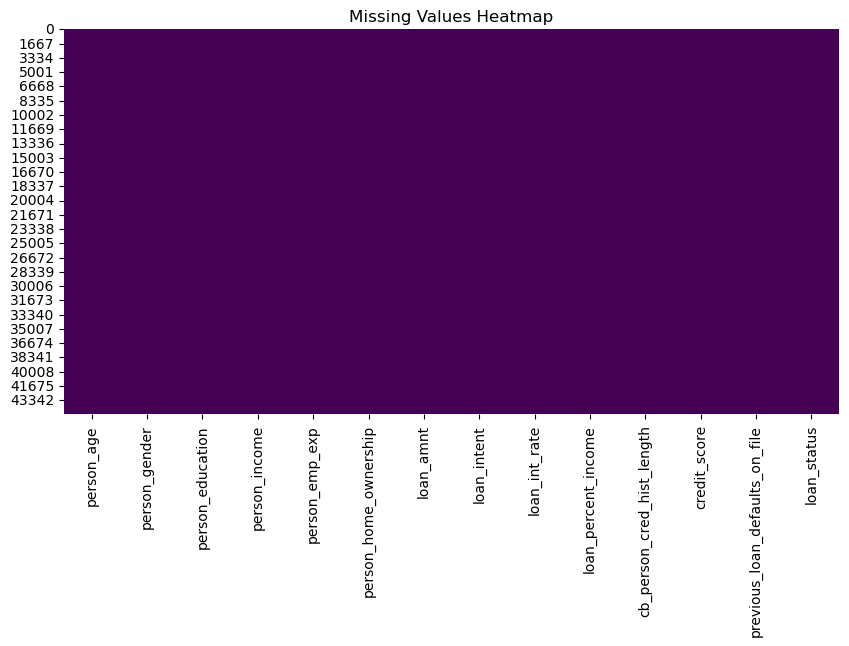

In [4]:
# heatmap to Visualize missing values
plt.figure(figsize=(10,5))
sns.heatmap(df.isnull(), cbar=False, cmap='viridis')
plt.title("Missing Values Heatmap")
plt.show()

**Task 2: Outlier Detection & Removal**

* We focused on person_income because it has the largest range and potential extreme values, which can skew the model.

* loan_amnt and loan_int_rate may be large ranges, but extreme values are rarer or already cut off by the bank’s rules.

In [5]:
numeric_cols = ['person_age','person_income','person_emp_exp',
                'loan_amnt','loan_int_rate','loan_percent_income',
                'cb_person_cred_hist_length','credit_score']

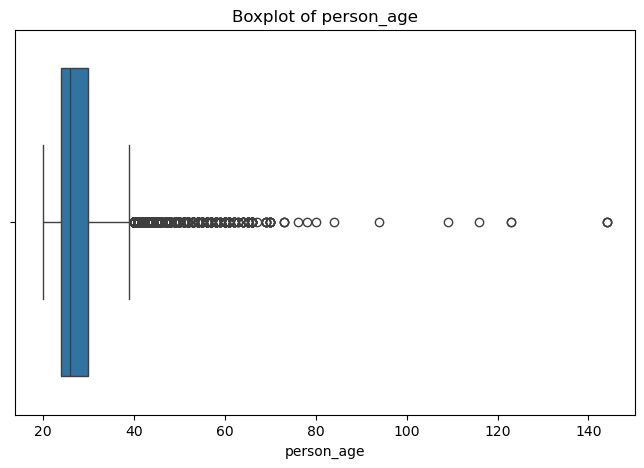

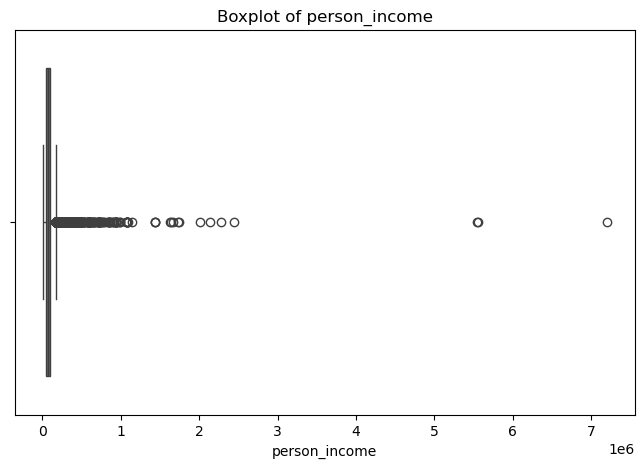

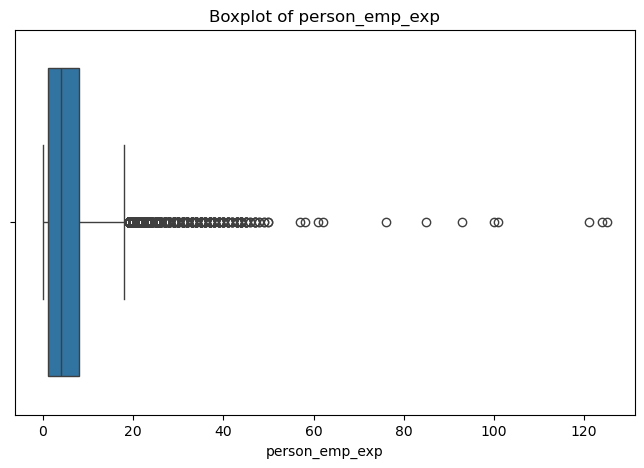

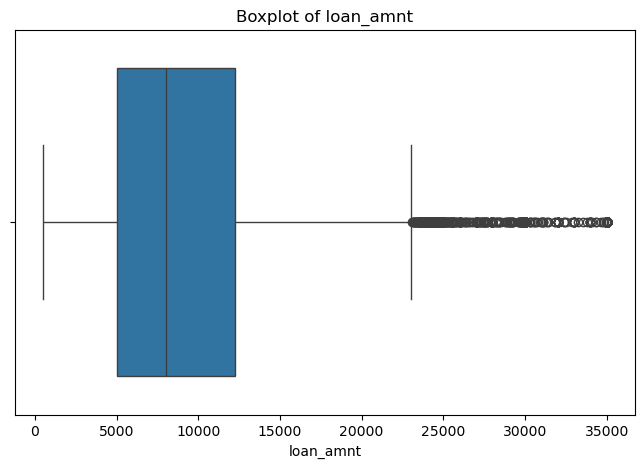

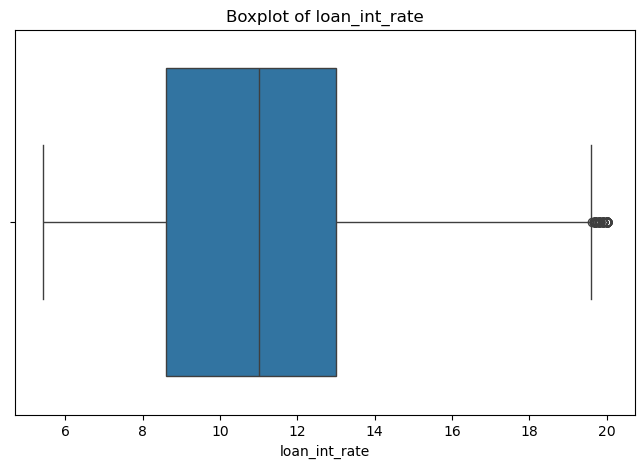

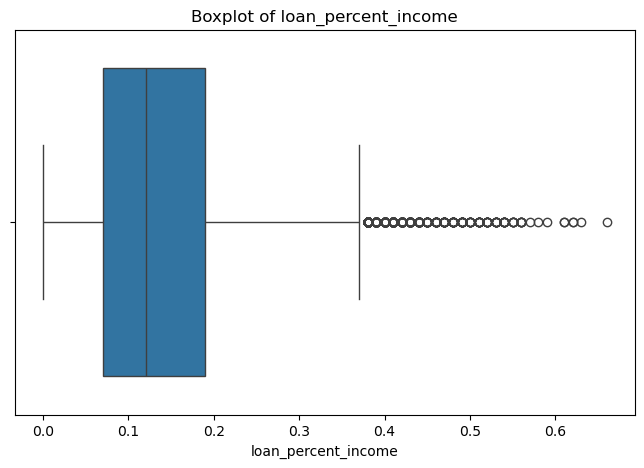

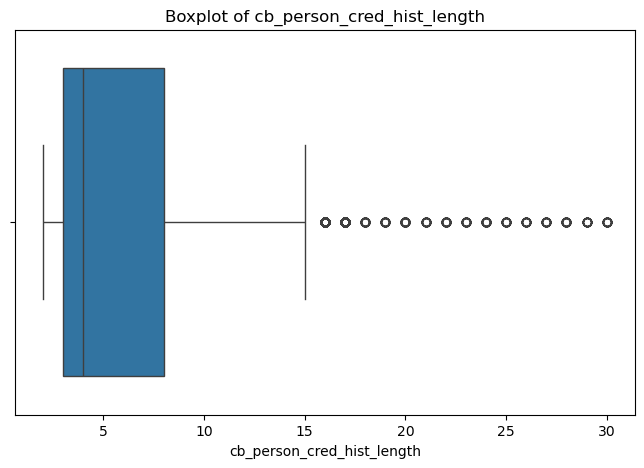

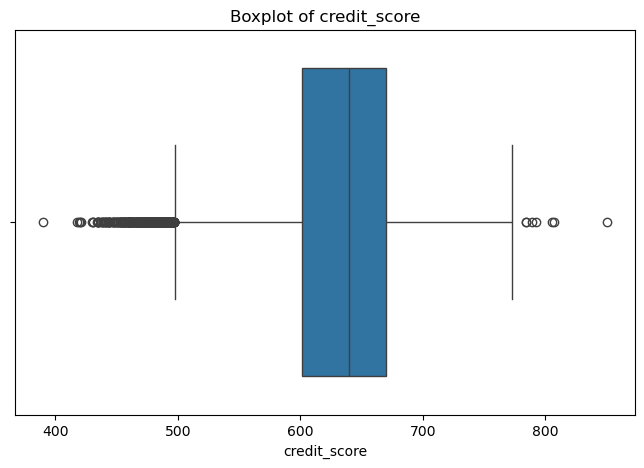

In [ ]:
# Visualize outliers with boxplot
for col in numeric_cols:
    plt.figure(figsize=(8,5))
    sns.boxplot(x=df[col])
    plt.title(f"Boxplot of {col}")
    plt.show()

In [ ]:
# Use IQR method to detect outliers in person_income
Q1 = df['person_income'].quantile(0.25)
Q3 = df['person_income'].quantile(0.75)
IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

print("Lower Bound:", lower_bound)
print("Upper Bound:", upper_bound)

Lower Bound: -25673.875
Upper Bound: 168667.125


In [ ]:
# Remove outliers
df_clean = df[(df['person_income'] >= lower_bound) & (df['person_income'] <= upper_bound)].copy()

In [9]:
print("Original shape:", df.shape)
print("After outlier removal:", df_clean.shape)

Original shape: (45000, 14)
After outlier removal: (42782, 14)


In [10]:
# List all numeric columns except 'person_income'
other_cols = ['person_age', 'person_emp_exp', 'loan_amnt', 
              'loan_int_rate', 'loan_percent_income', 
              'cb_person_cred_hist_length', 'credit_score']

for col in other_cols:
    Q1 = df_clean[col].quantile(0.25)
    Q3 = df_clean[col].quantile(0.75)
    IQR = Q3 - Q1

    lower = Q1 - 1.5*IQR
    upper = Q3 + 1.5*IQR

    df_clean = df_clean[(df_clean[col] >= lower) & (df_clean[col] <= upper)].copy()

In [11]:
print("Original shape:", df.shape)
print("After outlier removal:", df_clean.shape)

Original shape: (45000, 14)
After outlier removal: (36082, 14)


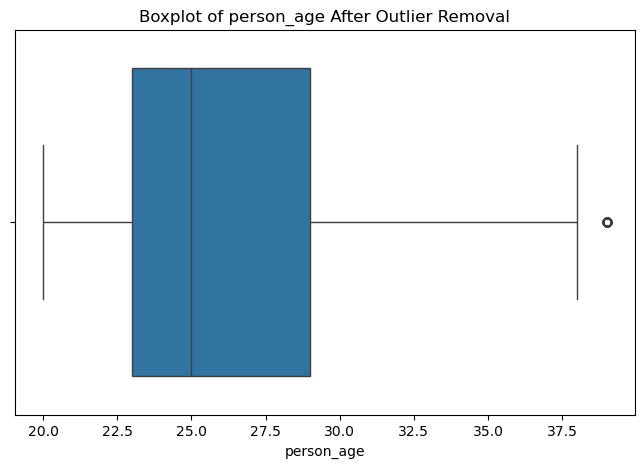

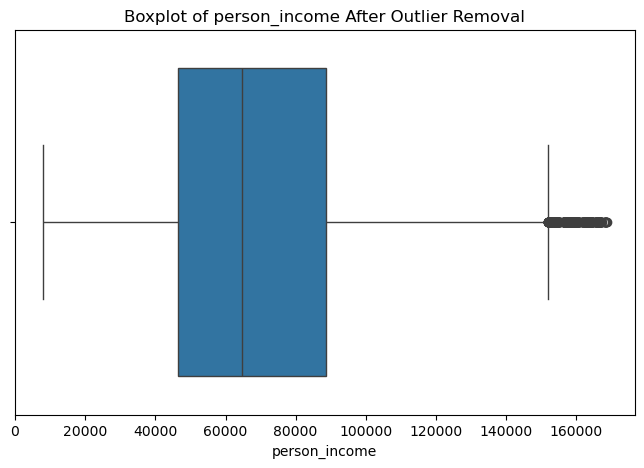

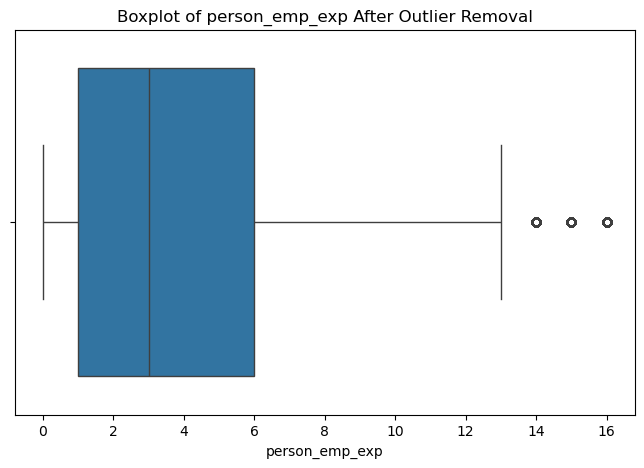

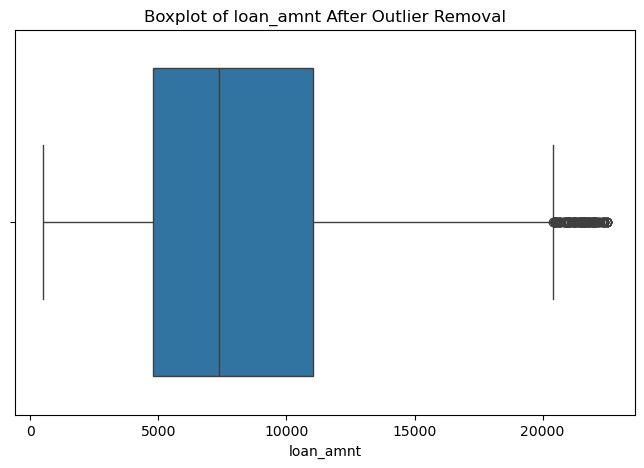

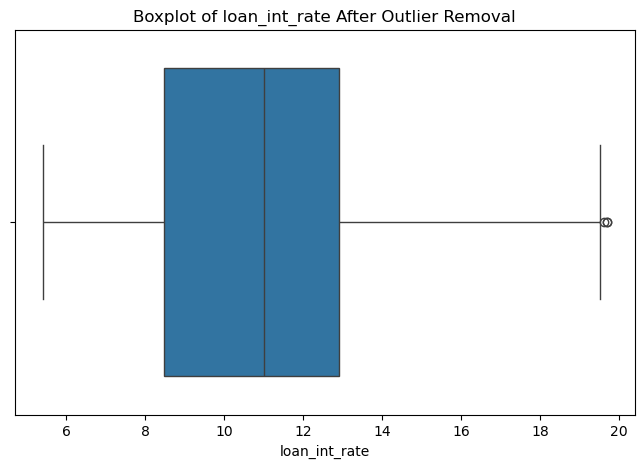

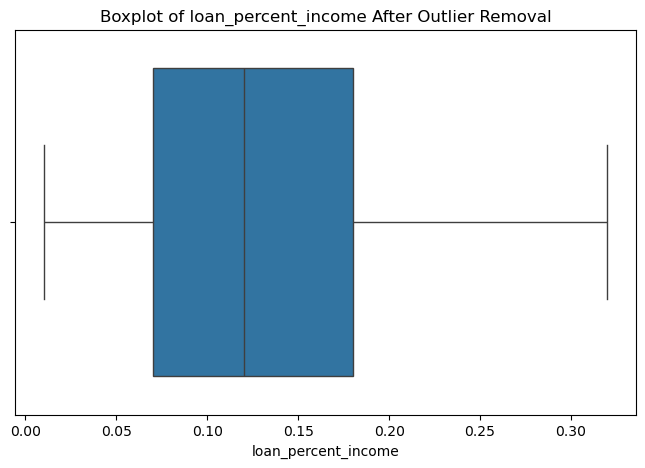

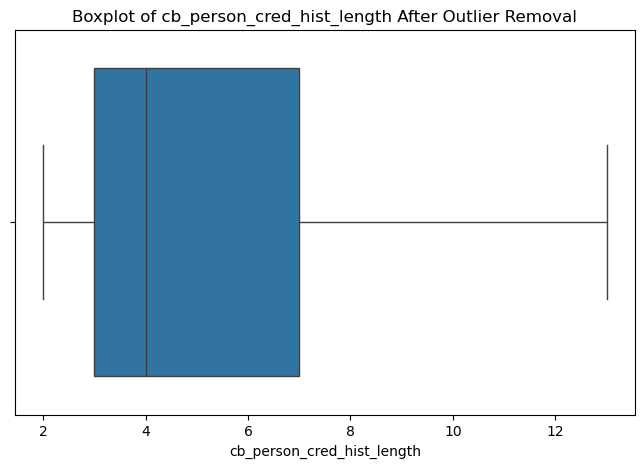

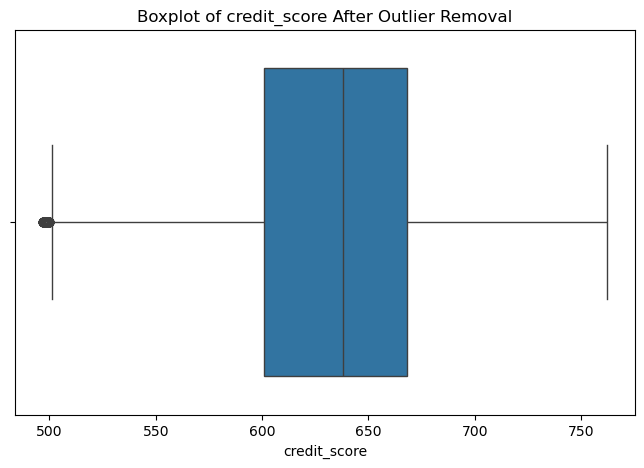

In [15]:
# 2. Boxplots after outlier removal
for col in numeric_cols:
    plt.figure(figsize=(8,5))
    sns.boxplot(x=df_clean[col])
    plt.title(f"Boxplot of {col} After Outlier Removal")
    plt.show()


In [16]:
# Create a new DataFrame with encoded categorical features
df_clean.to_csv('C:/Users/User/Desktop/PG230/PG230_Bank_Loan_default_prediction/results/outputs/missing_values.csv', index=False)